# Practical 11 - Monte Carlo and MCMC

This practical uses the monthly mean total sunspot number, from January 1749 to November 2018 (3239 months). Sunspots are cooler dark patches on the surface of the sun, and their number goes up and down in a cycle of about 11 years. I model the monthly counts with a gamma distribution and then use MCMC to estimate its two parameters, a and b.

Importing the libraries and loading the data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import gammaln

df = pd.read_csv("sunspots_1749_2018.csv")

print("Shape:", df.shape)
df.head()

Shape: (3239, 4)


,year,month,date,sunspots
0,1749,1,1749.042,96.7
1,1749,2,1749.123,104.3
2,1749,3,1749.204,116.7
3,1749,4,1749.288,92.8
4,1749,5,1749.371,141.7


### Step 1: Plot the data over the years

Plotting the monthly count against the year to see what the data looks like.

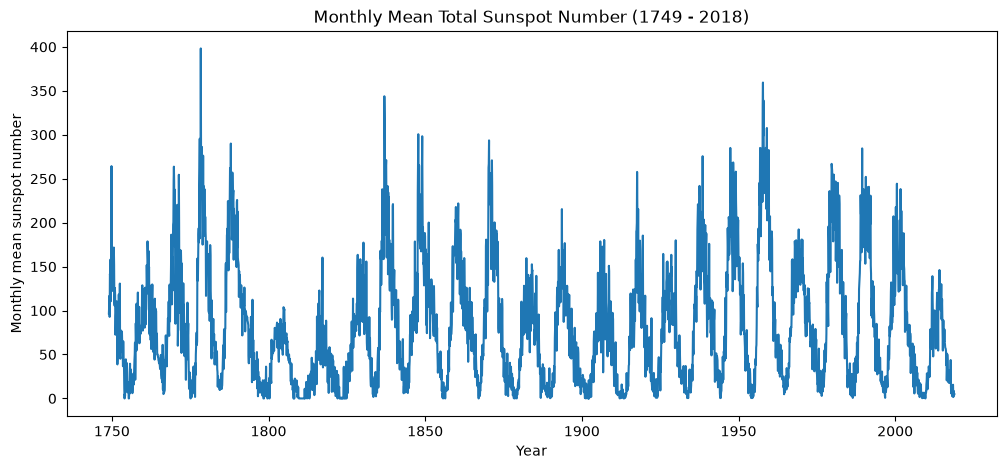

In [2]:
plt.figure(figsize=(12,5))
plt.plot(df["date"], df["sunspots"])
plt.xlabel("Year")
plt.ylabel("Monthly mean sunspot number")
plt.title("Monthly Mean Total Sunspot Number (1749 - 2018)")
plt.show()

The counts go up and down in waves, which are the solar cycles. The peaks are not all the same height, and the counts never go below 0.

### Step 2: Model with a gamma distribution, with a new cycle every 12 years

First I mark the cycles. A new cycle starts every 12 years (144 months), so each month gets a cycle number and a year number inside its cycle.

In [3]:
month_number = np.arange(len(df))

df["cycle"] = month_number // 144 + 1
df["year_in_cycle"] = (month_number % 144) // 12 + 1

print("Number of cycles:", df["cycle"].nunique())
print()
print(df.groupby("year_in_cycle")["sunspots"].mean().round(1))

Number of cycles: 23

year_in_cycle
1      82.8
2      93.1
3      99.5
4     102.7
5      99.3
6      89.4
7      80.6
8      76.2
9      70.2
10     63.0
11     61.1
12     67.4
Name: sunspots, dtype: float64


The average count rises for the first few years of a cycle, peaks around year 4 and then falls. The real solar cycle is about 11 years, so a 12-year reset drifts a little, but the shape is still there.

Now the gamma model. A gamma distribution has a shape a and a scale b, and it only allows positive values. There are 67 months with a count of exactly 0, so I replace those with 0.1 to make the model work. Then I fit the gamma with scipy to see roughly what a and b should be.

In [4]:
counts = df["sunspots"].clip(lower=0.1)

a_fit, loc_fit, b_fit = stats.gamma.fit(counts, floc=0)

print("Fitted shape a:", round(a_fit, 3))
print("Fitted scale b:", round(b_fit, 2))
print("Average count the model gives (a x b):", round(a_fit * b_fit, 2))
print("Average count in the data:", round(counts.mean(), 2))

Fitted shape a: 0.979
Fitted scale b: 84.18
Average count the model gives (a x b): 82.39
Average count in the data: 82.39


### Step 3: Histogram of sunspot counts

The histogram of all the monthly counts, with the fitted gamma curve on top.

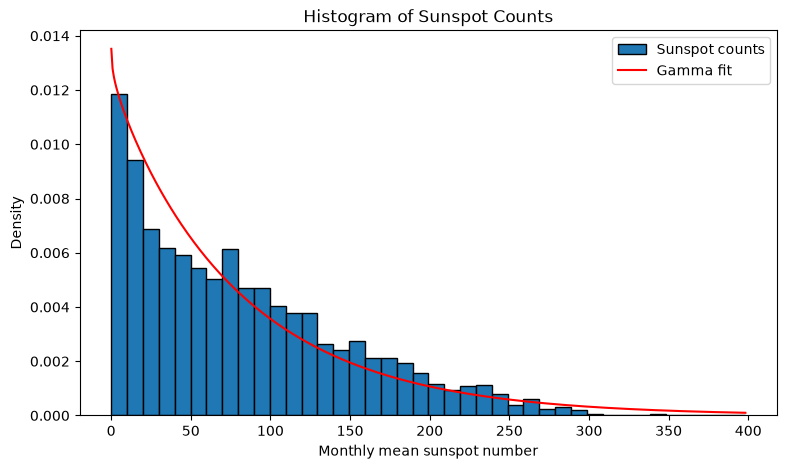

In [5]:
x = np.linspace(0.1, counts.max(), 500)

plt.figure(figsize=(9,5))
plt.hist(counts, bins=40, density=True, edgecolor="black", label="Sunspot counts")
plt.plot(x, stats.gamma.pdf(x, a_fit, scale=b_fit), color="red", label="Gamma fit")
plt.xlabel("Monthly mean sunspot number")
plt.ylabel("Density")
plt.title("Histogram of Sunspot Counts")
plt.legend()
plt.show()

Most months have low counts and there is a long tail of high ones, which is the typical gamma shape. The red curve follows the histogram quite well.

### Step 4: MCMC with a = 4 and b = 10

Now I estimate a and b with MCMC, using the Metropolis algorithm. I start the chain at a = 4 and b = 10. At each step it proposes a small random move, always accepts the move if the fit to the data gets better, and only sometimes accepts it if the fit gets worse. After many steps the samples show which values of a and b fit the data.

In [6]:
data = counts.values
n = len(data)
sum_data = data.sum()
sum_log_data = np.log(data).sum()

def log_posterior(a, b):
    # gamma log-likelihood of all the data, with a flat prior on a > 0 and b > 0
    if a <= 0 or b <= 0:
        return -np.inf
    return -n * gammaln(a) - n * a * np.log(b) + (a - 1) * sum_log_data - sum_data / b

In [7]:
np.random.seed(42)

n_samples = 5000
a, b = 4, 10               # starting values from the question
current = log_posterior(a, b)

a_trace = np.zeros(n_samples)
b_trace = np.zeros(n_samples)
accepted = 0

for i in range(n_samples):
    a_new = a + np.random.normal(0, 0.03)
    b_new = b + np.random.normal(0, 3)
    new = log_posterior(a_new, b_new)

    if np.log(np.random.uniform()) < new - current:
        a, b, current = a_new, b_new, new
        accepted += 1

    a_trace[i] = a
    b_trace[i] = b

print("Samples:", n_samples)
print("Acceptance rate:", round(accepted / n_samples, 3))

Samples: 5000
Acceptance rate: 0.315


Plotting the chain for three groups of samples: the first 50, all of them, and the last 50.

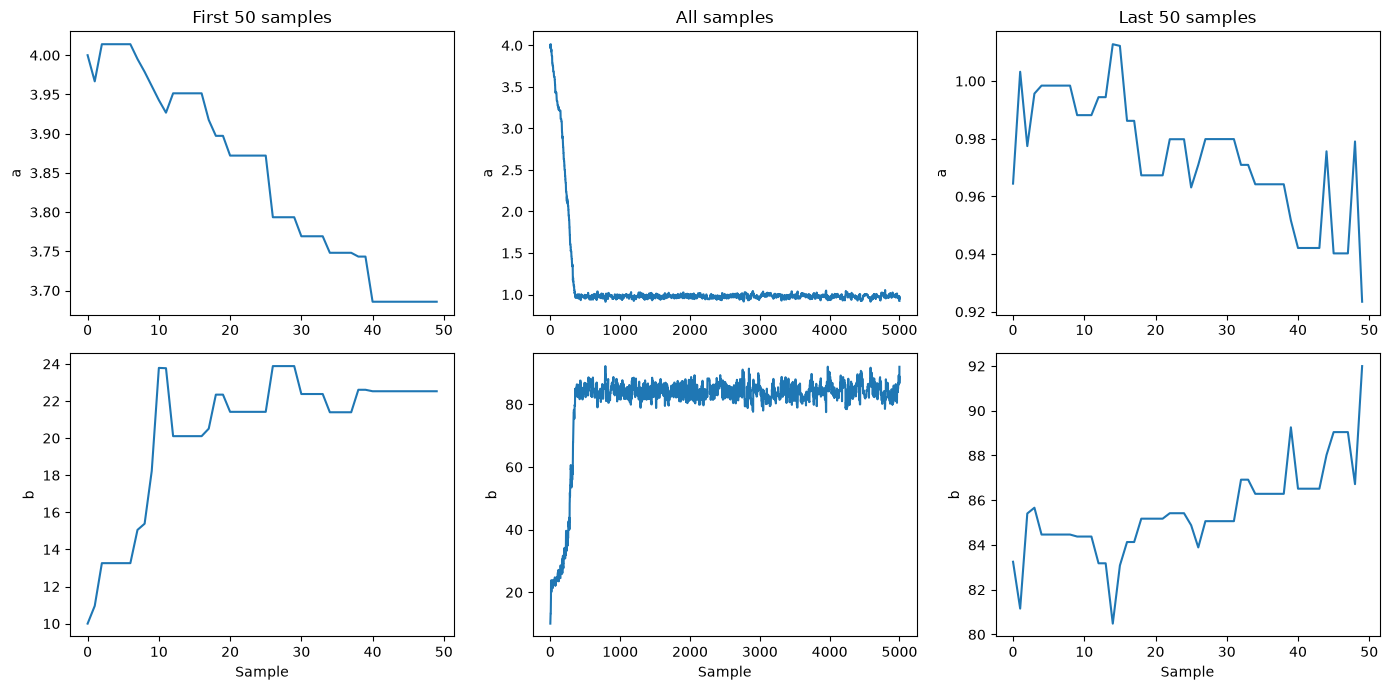

In [8]:
groups = {
    "First 50 samples": slice(0, 50),
    "All samples": slice(0, n_samples),
    "Last 50 samples": slice(n_samples - 50, n_samples),
}

plt.figure(figsize=(14,7))
for i, (name, sl) in enumerate(groups.items()):
    plt.subplot(2, 3, i + 1)
    plt.plot(a_trace[sl])
    plt.title(name)
    plt.ylabel("a")

    plt.subplot(2, 3, i + 4)
    plt.plot(b_trace[sl])
    plt.xlabel("Sample")
    plt.ylabel("b")
plt.tight_layout()
plt.show()

In the first 50 samples both a and b are still moving away from the starting values of 4 and 10. In the full chain they settle after a few hundred samples and then just wiggle around a steady level. The last 50 samples stay in a narrow band, so the chain has settled.

### Step 5: Traces of a and b and their histograms (dropping the burn-in)

The first part of the chain is just the walk away from the starting point, so it should not be used for the estimates. That part is called the burn-in. From the plot above the chain settles within a few hundred samples, so I drop the first 500 to be safe.

Samples kept: 4500


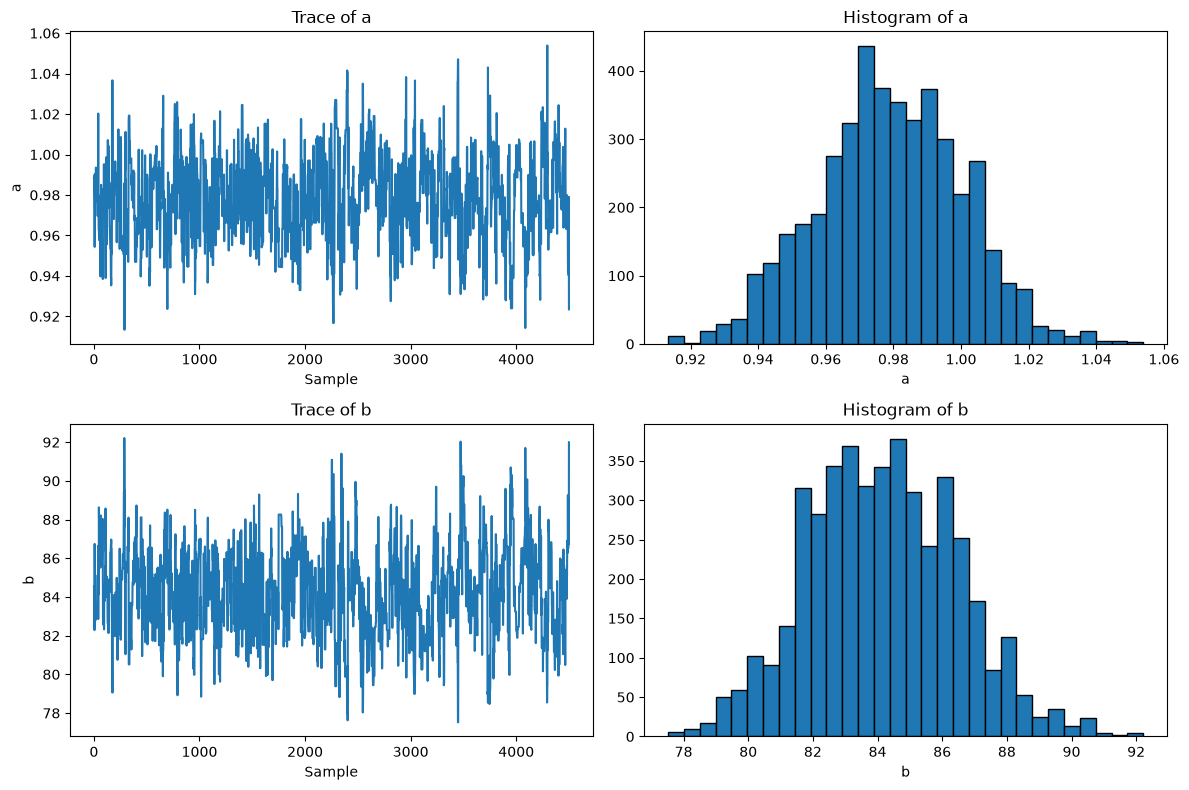

In [9]:
burn_in = 500

a_clean = a_trace[burn_in:]
b_clean = b_trace[burn_in:]

print("Samples kept:", len(a_clean))

plt.figure(figsize=(12,8))

plt.subplot(2, 2, 1)
plt.plot(a_clean)
plt.title("Trace of a")
plt.xlabel("Sample")
plt.ylabel("a")

plt.subplot(2, 2, 2)
plt.hist(a_clean, bins=30, edgecolor="black")
plt.title("Histogram of a")
plt.xlabel("a")

plt.subplot(2, 2, 3)
plt.plot(b_clean)
plt.title("Trace of b")
plt.xlabel("Sample")
plt.ylabel("b")

plt.subplot(2, 2, 4)
plt.hist(b_clean, bins=30, edgecolor="black")
plt.title("Histogram of b")
plt.xlabel("b")

plt.tight_layout()
plt.show()

Both traces look steady with no trend, and both histograms are bell shaped. So a is close to 1 and b is around 84.

### Step 6: Prediction of a and b

Taking the samples after burn-in, the average is the estimate for a and b, and the 2.5% and 97.5% values give a 95% range.

In [10]:
results = pd.DataFrame({
    "mean": [a_clean.mean(), b_clean.mean()],
    "std": [a_clean.std(), b_clean.std()],
    "2.5%": [np.percentile(a_clean, 2.5), np.percentile(b_clean, 2.5)],
    "97.5%": [np.percentile(a_clean, 97.5), np.percentile(b_clean, 97.5)],
}, index=["a", "b"]).round(3)

print(results)

print()
print("Predicted average monthly count (a x b):", round(a_clean.mean() * b_clean.mean(), 2))
print("Actual average in the data:", round(counts.mean(), 2))
print("Scipy fit for comparison: a =", round(a_fit, 3), ", b =", round(b_fit, 2))

     mean    std    2.5%   97.5%
a   0.979  0.022   0.938   1.019
b  84.161  2.312  79.862  88.777

Predicted average monthly count (a x b): 82.39
Actual average in the data: 82.39
Scipy fit for comparison: a = 0.979 , b = 84.18


The MCMC estimates are very close to the scipy fit from step 2, and the predicted average count matches the real average in the data.

## Conclusion

The monthly sunspot counts rise and fall in cycles and are well described by a gamma distribution, with a shape a of about 1 and a scale b of about 84. Starting the MCMC from a = 4 and b = 10, the chain moved to those values within a few hundred samples, which is why the first 500 were dropped as burn-in. The estimates after burn-in agree with the direct scipy fit, and they give a predicted average of about 82 sunspots per month, which matches the data.